In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path("outputs/bearing_features.csv")

df = pd.read_csv(DATA_PATH)

print("Jumlah segmen:", len(df))
print("Jumlah rekaman:", df["source_file"].nunique())

print("\nDistribusi kondisi bearing:")
print(df["condition"].value_counts())

print("\nJumlah rekaman setiap kondisi:")
print(
    df.groupby("condition")["source_file"].nunique()
)

print("\nContoh dataset:")
display(df.head())


Jumlah segmen: 3993
Jumlah rekaman: 40

Distribusi kondisi bearing:
condition
Outer Race    1215
Inner Race    1213
Ball Fault    1213
Normal         352
Name: count, dtype: int64

Jumlah rekaman setiap kondisi:
condition
Ball Fault    12
Inner Race    12
Normal         4
Outer Race    12
Name: source_file, dtype: int64

Contoh dataset:


,source_file,segment_id,start_sample,end_sample,condition,defect_size_inch,motor_load_hp,mean,std,rms,...,peak_amplitude,crest_factor,dominant_frequency,spectral_centroid,spectral_bandwidth,spectral_entropy,total_spectral_power,band_power_low,band_power_mid,band_power_high
0,97.mat,0,0,1199,Normal,NaN,0,-0.000437,0.072389,0.072390,...,0.216706,2.993599,4148.4375,3076.863339,1588.327631,5.084973,0.004946,0.001197,0.000463,0.003284
1,97.mat,1,1200,2399,Normal,NaN,0,0.000018,0.069990,0.069990,...,0.242119,3.459334,4148.4375,3169.305563,1537.997776,5.200270,0.004990,0.001109,0.000463,0.003413
2,97.mat,2,2400,3599,Normal,NaN,0,-0.000180,0.068403,0.068404,...,0.247259,3.614699,4148.4375,3291.095042,1460.725365,5.149379,0.004693,0.000829,0.000444,0.003418
3,97.mat,3,3600,4799,Normal,NaN,0,0.000025,0.070061,0.070061,...,0.244666,3.492195,4148.4375,3225.832963,1485.812198,5.089351,0.004650,0.000933,0.000481,0.003236
4,97.mat,4,4800,5999,Normal,NaN,0,-0.000124,0.069863,0.069863,...,0.210170,3.008313,4148.4375,3150.739684,1549.269331,5.254523,0.004976,0.001069,0.000460,0.003446


In [2]:
# Menentukan fitur dan target
# 16 fitur hasil feature engineering
feature_columns = [
    "mean", "std", "rms", "skewness",
    "kurtosis", "peak_to_peak",
    "peak_amplitude", "crest_factor",
    "dominant_frequency", "spectral_centroid",
    "spectral_bandwidth", "spectral_entropy",
    "total_spectral_power",
    "band_power_low", "band_power_mid",
    "band_power_high"
]

X = df[feature_columns]
y = df["condition"]
groups = df["source_file"]

print("Jumlah fitur:", X.shape[1])
print("Jumlah segmen:", X.shape[0])
print("Target klasifikasi:", sorted(y.unique()))


Jumlah fitur: 16
Jumlah segmen: 3993
Target klasifikasi: ['Ball Fault', 'Inner Race', 'Normal', 'Outer Race']


In [3]:
# Membagi training dan testing berdasarkan rekaman
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_files = set(groups.iloc[train_idx])
test_files = set(groups.iloc[test_idx])

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("\nJumlah file training:", len(train_files))
print("Jumlah file testing:", len(test_files))

print("\nDistribusi kelas training:")
print(y_train.value_counts())

print("\nDistribusi kelas testing:")
print(y_test.value_counts())

assert train_files.isdisjoint(test_files), (
    "Data leakage: ada file yang masuk train dan test!"
)

print("\nTidak ada rekaman yang tumpang tindih.")


Jumlah data training: 2981
Jumlah data testing: 1012

Jumlah file training: 30
Jumlah file testing: 10

Distribusi kelas training:
condition
Outer Race    911
Ball Fault    910
Inner Race    909
Normal        251
Name: count, dtype: int64

Distribusi kelas testing:
condition
Inner Race    304
Outer Race    304
Ball Fault    303
Normal        101
Name: count, dtype: int64

Tidak ada rekaman yang tumpang tindih.


In [4]:
# Melatih Random Forest
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

print("Random Forest berhasil dilatih!")


Random Forest berhasil dilatih!


In [5]:
# Prediksi dan evaluasi model
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model_rf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Akurasi: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)


Akurasi: 99.60%

Classification Report:
              precision    recall  f1-score   support

  Ball Fault       0.99      1.00      0.99       303
  Inner Race       1.00      1.00      1.00       304
      Normal       1.00      1.00      1.00       101
  Outer Race       1.00      0.99      0.99       304

    accuracy                           1.00      1012
   macro avg       1.00      1.00      1.00      1012
weighted avg       1.00      1.00      1.00      1012



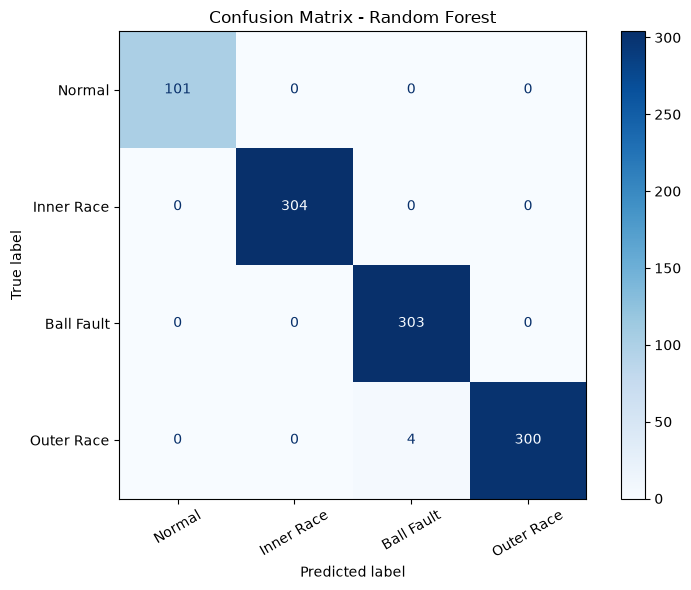

In [6]:
# Confusion Matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

labels = [
    "Normal",
    "Inner Race",
    "Ball Fault",
    "Outer Race"
]

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=labels,
    cmap="Blues",
    ax=ax,
    values_format="d"
)

plt.title("Confusion Matrix - Random Forest")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


,Feature,Importance
5,peak_to_peak,0.191100
6,peak_amplitude,0.121768
1,std,0.118824
14,band_power_mid,0.113525
2,rms,0.113229
15,band_power_high,0.072046
12,total_spectral_power,0.062659
10,spectral_bandwidth,0.061378
4,kurtosis,0.031144
8,dominant_frequency,0.030030


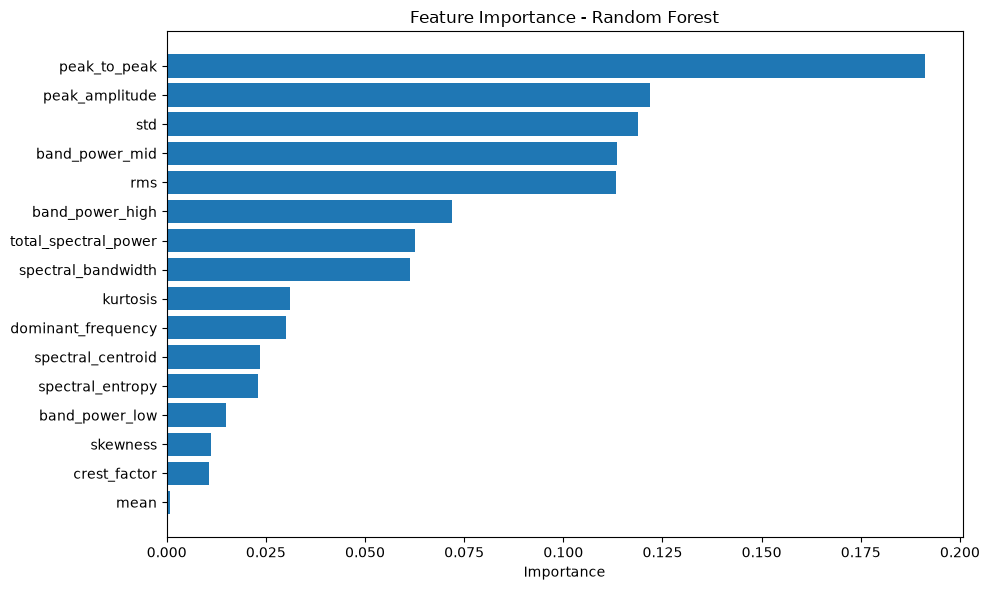

In [7]:
# Feature Importance
importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": model_rf.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


# Cross-Validation Random Forest

In [8]:
# Evaluasi menggunakan Stratified Group K-Fold
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

cv_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups), start=1
):
    X_tr = X.iloc[train_idx]
    X_te = X.iloc[test_idx]

    y_tr = y.iloc[train_idx]
    y_te = y.iloc[test_idx]

    # Memastikan seluruh kelas tersedia
    if set(y_tr.unique()) != set(y.unique()):
        raise ValueError(
            f"Fold {fold}: kelas training tidak lengkap."
        )

    if set(y_te.unique()) != set(y.unique()):
        raise ValueError(
            f"Fold {fold}: kelas testing tidak lengkap."
        )

    # Model baru pada setiap fold
    fold_model = clone(model_rf)
    fold_model.fit(X_tr, y_tr)

    predictions = fold_model.predict(X_te)

    cv_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_te, predictions),
        "Precision": precision_score(
            y_te, predictions,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_te, predictions,
            average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_te, predictions,
            average="macro", zero_division=0
        ),
        "Test Recordings": groups.iloc[test_idx].nunique()
    })

cv_df = pd.DataFrame(cv_results)

display(cv_df.round(4))


,Fold,Accuracy,Precision,Recall,F1-Score,Test Recordings
0,1,0.9960,0.9967,0.9967,0.9967,10
1,2,0.9020,0.9302,0.9183,0.9189,10
2,3,0.8917,0.9232,0.7724,0.8011,10
3,4,0.9496,0.9598,0.9580,0.9579,10


,Mean,Std
Accuracy,0.9348,0.0480
Precision,0.9525,0.0335
Recall,0.9113,0.0980
F1-Score,0.9187,0.0845


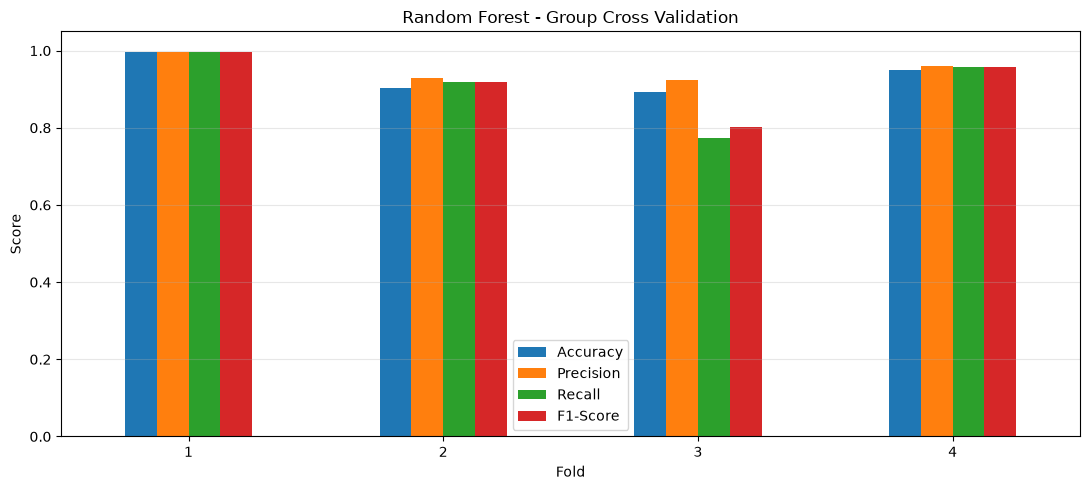

In [9]:
# Ringkasan performa cross-validation
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

summary_cv = pd.DataFrame({
    "Mean": cv_df[metrics].mean(),
    "Std": cv_df[metrics].std()
})

display(summary_cv.round(4))

ax = cv_df.set_index("Fold")[metrics].plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_title("Random Forest - Group Cross Validation")
ax.set_xlabel("Fold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:
# xport Random Forest
import joblib

MODEL_PATH = Path("outputs/models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# Model dari split awal, bukan model tiap fold
joblib.dump(
    {
        "model": model_rf,
        "feature_columns": feature_columns,
        "target": "condition",
        "classes": list(model_rf.classes_)
    },
    MODEL_PATH / "random_forest_condition.joblib"
)

cv_df.to_csv(
    "outputs/rf_cross_validation.csv",
    index=False
)

importance_df.to_csv(
    "outputs/rf_feature_importance.csv",
    index=False
)

print("Model dan hasil evaluasi berhasil disimpan.")


Model dan hasil evaluasi berhasil disimpan.
